# **TUGAS WEEK 6 STREAM AND TIME SERIES MINING**

Nama dan NIM Anggota :
1. BIMA SETIA SUGIHARTO (24031554040)
2. YANAKA SOFIA PARDEDE (24031554065)

Kelas : 2024B

# **Import Library**

Library yang digunakan dalam analisis data ini yaitu *pandas* dan *numpy* untuk pengolahan dan manipulasi data, *matplotlib* dan *seaborn* untuk visualisasi data, dan *library river* untuk melakukan analisis pada stream data secara online, seperti pemodelan dan clustering. Selain itu, untuk menampilkan output yang lebih rapi pada notebook digunakan *IPython.display*.

In [ ]:
pip install river

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from river import tree, stream, metrics, cluster
from IPython.display import display

# **DATASET TIME SERIES**

Analisis ini menggunakan dataset Amazon Sales and Trading Insights 2024 yang diperoleh dari platform Kaggle. Dataset tersebut kami akses melalui link berikut:

https://www.kaggle.com/datasets/nalisha/amazon-sales-and-trading-insights-dataset-2024

Dataset ini berisi informasi tentang setiap transaksi penjualan produk Amazon, mencakup tanggal pemesanan (*order_date*), nama produk, kategori produk, jumlah unit terjual, harga produk, dan total nilai penjualan. Karena memiliki variabel waktu order_date, dataset ini digunakan untuk analisis time series. Variabel waktu ini memungkinkan untuk mengidentifikasi pola penjualan, menganalisis tren penjualan dari waktu ke waktu, dan membuat model prediksi penjualan untuk masa depan.

## **Load Dataset From GDrive**

Proses ini dilakukan dengan menggunakan fungsi mount untuk menghubungkan Google Colab dengan Google Drive. Dengan demikian, file yang tersimpan di Google Drive dapat diakses dalam Python. Setelah terhubung ke Google Drive, file dataset dibaca dengan library pandas menggunakan fungsi read_csv() dan disimpan ke dalam dataframe.

1. Untuk mengetahui jumlah baris dan kolom yang terdapat dalam dataframe, perintah *df.shape* digunakan, hasilnya menunjukkan bahwa dataset ini memiliki 10.000 baris data dan 21 kolom, yang berarti bahwa ada 10.000 data transaksi dengan 21 variabel.
2. Nama-nama kolom atau variabel dalam dataset ditampilkan dengan perintah *df.columns*, untuk memahami struktur dataset dan memudahkan proses analisis data selanjutnya, seperti memilih variabel untuk eksplorasi, visualisasi, atau pemodelan data.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [130]:
path = "/content/drive/Shareddrives/STREAM AND TIME SERIES MINING/amazon_sales_dataset.csv"
df = pd.read_csv(path)
df.head()

,order_id,order_date,ship_date,delivery_date,order_status,customer_id,customer_name,country,state,city,...,product_name,category,sub_category,brand,quantity,unit_price,discount,shipping_cost,total_sales,payment_method
0,A10000,2026-01-31,2026-01-31,2026-01-08,Delivered,C5691,Ricky Potter,India,South Carolina,New Joe,...,without,Home,Furniture,Doyle-Jordan,3,42467.79,0.26,60.85,94339.3438,Card
1,A10001,2026-01-20,2026-02-03,2026-02-03,Delivered,C9811,Chris Davenport,India,Tennessee,Madisonmouth,...,school,Home,Furniture,Davis LLC,2,36138.76,0.24,112.96,55043.8752,COD
2,A10002,2026-01-15,2026-02-07,2026-01-03,Delivered,C7341,Timothy Gallagher,India,Iowa,East Larryberg,...,I,Electronics,Laptop,Watson and Sons,4,47148.93,0.14,64.11,162256.4292,UPI
3,A10003,2026-01-18,2026-01-15,2026-01-20,Delivered,C4012,Angela Collins,India,Kentucky,South Margaretshire,...,step,Electronics,Laptop,"Sandoval, Buckley and Solis",1,18487.99,0.06,114.15,17492.8606,Card
4,A10004,2026-01-27,2026-01-04,2026-01-23,Delivered,C1328,David Davidson DDS,India,North Dakota,Velasquezview,...,bit,Home,Kitchen,"Key, Bautista and Bowen",1,1742.25,0.10,40.47,1608.4950,UPI


In [131]:
df.shape

(10000, 21)

In [132]:
df.columns

Index(['order_id', 'order_date', 'ship_date', 'delivery_date', 'order_status',
       'customer_id', 'customer_name', 'country', 'state', 'city',
       'product_id', 'product_name', 'category', 'sub_category', 'brand',
       'quantity', 'unit_price', 'discount', 'shipping_cost', 'total_sales',
       'payment_method'],
      dtype='object')

## **Data Understanding**

Tahap ini memberikan informasi tentang struktur dan karakteristik dataset. Proses ini termasuk memeriksa informasi dataset, melakukan statistik deskriptif, dan memeriksa nilai yang hilang.
1. Ringkasan statistik dari variabel numerik diperoleh dengan menggunakan *df.describe()*. Variabel quantity memiliki nilai minimum sebesar 1 dan nilai maksimum sebesar 5, dengan rata-rata sekitar 3 unit per transaksi. Jumlah variabel harga unit rata-rata sekitar 25126.51, dengan potongan harga rata-rata 0,14. Sedangkan shipping_cost memiliki rata-rata sekitar 85.05 dan variabel total_sales memiliki rata-rata sekitar 64212.91
2. Dataset ini memiliki 10.000 baris data dan 21 kolom variabel dari berbagai tipe data, yaitu object, integer, dan float yang ditunjukkan oleh *df.info()*
3. Dengan menggunakan *df.isnull().sum()*, menunjukkan semua variabel dalam dataset bernilai 0, berarti tidak terdapat missing value pada dataset ini. Oleh karena itu, dataset dapat digunakan langsung untuk proses analisis berikutnya tanpa perlu melakukan tahap penanganan.

In [133]:
df.describe()

,quantity,unit_price,discount,shipping_cost,total_sales
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000
mean,3.01440,25126.511133,0.149968,85.053192,64212.910555
std,1.42035,14343.922332,0.086828,37.575284,50992.635082
min,1.00000,214.200000,0.000000,20.010000,309.939600
25%,2.00000,12657.827500,0.070000,52.507500,24037.196775
50%,3.00000,24880.490000,0.150000,84.995000,50287.177500
75%,4.00000,37544.640000,0.220000,117.680000,93417.891825
max,5.00000,49981.880000,0.300000,149.950000,249155.530000


In [134]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        10000 non-null  object 
 1   order_date      10000 non-null  object 
 2   ship_date       10000 non-null  object 
 3   delivery_date   10000 non-null  object 
 4   order_status    10000 non-null  object 
 5   customer_id     10000 non-null  object 
 6   customer_name   10000 non-null  object 
 7   country         10000 non-null  object 
 8   state           10000 non-null  object 
 9   city            10000 non-null  object 
 10  product_id      10000 non-null  object 
 11  product_name    10000 non-null  object 
 12  category        10000 non-null  object 
 13  sub_category    10000 non-null  object 
 14  brand           10000 non-null  object 
 15  quantity        10000 non-null  int64  
 16  unit_price      10000 non-null  float64
 17  discount        10000 non-null  

In [135]:
df.isnull().sum()

,0
order_id,0
order_date,0
ship_date,0
delivery_date,0
order_status,0
customer_id,0
customer_name,0
country,0
state,0
city,0


## **Data Preprocessing**

1. Pertama, kolom *order_date* diubah ke dalam format datetime menggunakan fungsi *pd.to_datetime()*, agar kolom tanggal dapat dikenali sebagai data waktu sehingga memudahkan analisis berdasarkan urutan waktu.

2. Kedua, dataset diurutkan berdasarkan kolom *order_date* menggunakan fungsi *sort_values()*. Pengurutan ini penting karena data harus tersusun secara kronologis dari waktu paling awal hingga paling akhir.

3. Ketiga, dilakukan proses agregasi data penjualan per hari dengan menggunakan fungsi *groupby()* pada kolom *order_date* dan menjumlahkan nilai pada kolom *total_sales*. Sehingga menghasilkan dataset baru yang berisi total penjualan setiap hari, yang nantinya akan digunakan untuk melihat tren penjualan dari waktu ke waktu.

In [136]:
df['order_date'] = pd.to_datetime(df['order_date'])

In [137]:
df = df.sort_values('order_date')

In [138]:
daily_sales = df.groupby('order_date')['total_sales'].sum()
daily_sales.head()

,total_sales
order_date,
2026-01-01,1.381286e+07
2026-01-02,1.657335e+07
2026-01-03,1.629792e+07
2026-01-04,1.591576e+07
2026-01-05,1.613404e+07


## **Exploratory Data Analysis (EDA)**

Exploratory Data Analysis (EDA) merupakan tahap awal dalam analisis data yang bertujuan untuk memahami karakteristik, pola, serta hubungan yang terdapat dalam dataset. Pada tahap ini dilakukan proses eksplorasi melalui visualisasi dan ringkasan statistik untuk melihat distribusi data, tren yang terjadi, serta potensi pola yang dapat digunakan dalam analisis selanjutnya.

In [139]:
import seaborn as sns
sns.set_style("whitegrid")

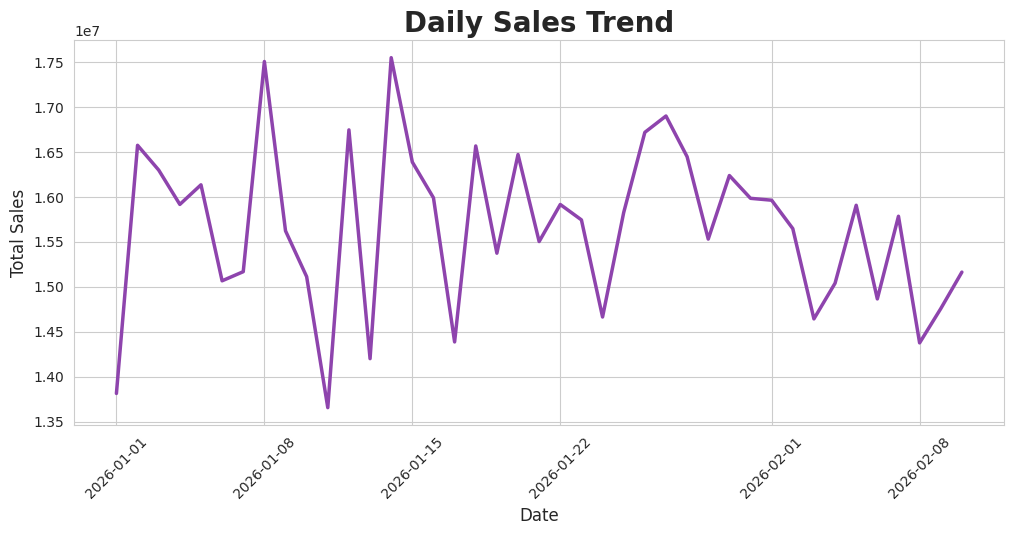

In [140]:
# DAILY SALES TREND

plt.figure(figsize=(12,5))
plt.plot(daily_sales, color="#8E44AD", linewidth=2.5)
plt.title("Daily Sales Trend", fontsize=20, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.xticks(rotation=45)
plt.show()

## **INSIGHT :**

Grafik Daily Sales Trend menunjukkan total penjualan harian yang diperoleh setelah menjalankan proses agregasi data pada dataset menggunakan Python. Berdasarkan output grafik yang dihasilkan, terlihat bahwa nilai penjualan harian berada pada kisaran sekitar 13 juta hingga 17 juta. Pola garis pada grafik memperlihatkan adanya fluktuasi naik dan turun dari hari ke hari, yang menunjukkan bahwa jumlah transaksi yang terjadi setiap harinya tidak selalu stabil.

Visualisasi grafik menggunakan warna ungu yang membantu memperjelas garis pergerakan penjualan sehingga perubahan nilai antar waktu dapat terlihat dengan lebih jelas. Dari grafik tersebut, kami melihat bahwa meskipun terdapat beberapa lonjakan penjualan pada hari tertentu, secara umum pola penjualan harian bersifat dinamis dan berubah-ubah, yang merupakan karakteristik umum pada data time series.

/tmp/ipykernel_541/3622386168.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_sales = df.resample('M', on='order_date')['total_sales'].sum()


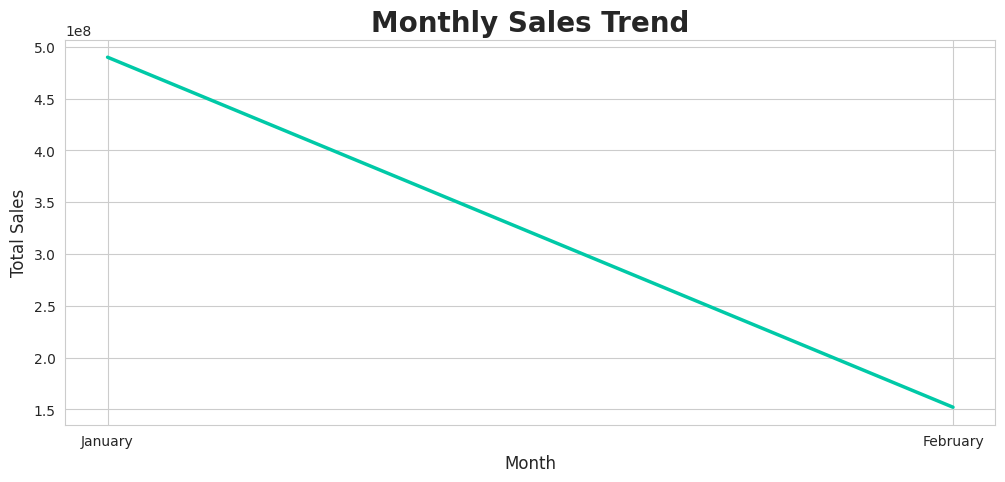

In [141]:
# MONTHLY SALES TREND

monthly_sales = df.resample('M', on='order_date')['total_sales'].sum()
monthly_sales.index = monthly_sales.index.strftime('%B')

plt.figure(figsize=(12,5))
plt.plot(monthly_sales, color="#00C9A7", linewidth=2.5)
plt.title("Monthly Sales Trend", fontsize=20, fontweight='bold')
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.show()

## **INSIGHT :**

Grafik Monthly Sales Trend menampilkan total penjualan yang telah diakumulasi setiap bulan melalui proses resampling pada data tanggal. Berdasarkan output grafik yang dihasilkan setelah kode dijalankan, terlihat bahwa nilai total penjualan mengalami penurunan secara bertahap dari awal hingga akhir periode pengamatan. Hal ini terlihat dari garis grafik yang cenderung bergerak menurun sepanjang periode waktu.

Grafik ini divisualisasikan menggunakan warna hijau kebiruan untuk membedakan tampilan dari grafik sebelumnya sekaligus memberikan visual yang lebih jelas. Dari hasil visualisasi ini, kami dapat memahami bahwa meskipun penjualan harian mengalami fluktuasi, secara agregat pada tingkat bulanan terdapat kecenderungan penurunan total penjualan selama periode analisis.

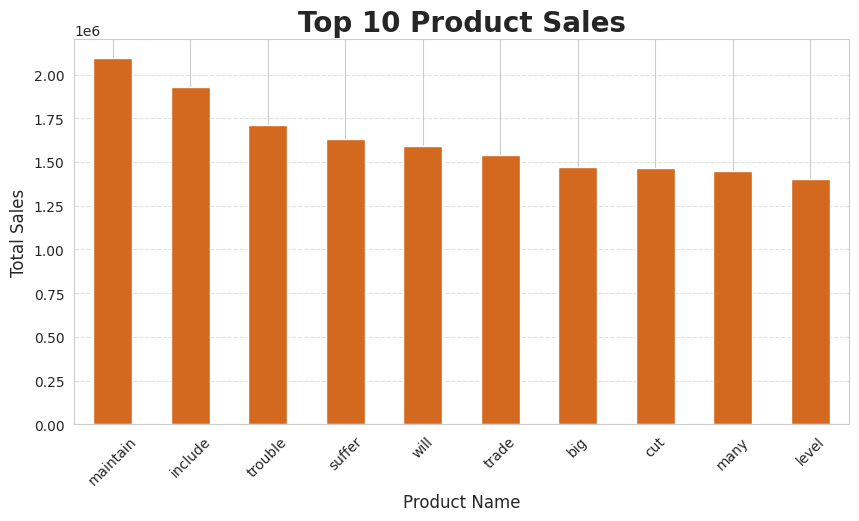

In [142]:
# TOP 10 PRODUCT SALES

top_products = df.groupby('product_name')['total_sales'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
top_products.plot(kind='bar', color="#D2691E")

plt.title("Top 10 Product Sales", fontsize=20, fontweight='bold')
plt.xlabel("Product Name", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

## **INSIGHT :**

Grafik Top 10 Product Sales menampilkan sepuluh produk dengan total penjualan tertinggi yang diperoleh setelah menjalankan proses pengelompokan data menggunakan fungsi groupby dan penjumlahan total penjualan pada setiap produk. Berdasarkan output grafik yang dihasilkan, terlihat bahwa produk dengan penjualan tertinggi adalah “maintain” dengan total penjualan sekitar 2,1 juta, diikuti oleh produk “include” dan “trouble” yang juga memiliki nilai penjualan yang cukup tinggi dibandingkan produk lainnya.

Grafik ini divisualisasikan dalam bentuk diagram batang dengan warna oranye sehingga perbedaan total penjualan antar produk dapat terlihat dengan jelas. Dari visualisasi tersebut, kami dapat melihat bahwa beberapa produk memiliki kontribusi penjualan yang lebih besar dibandingkan produk lainnya, sehingga produk-produk tersebut berpotensi menjadi produk yang paling diminati oleh konsumen dan dapat menjadi fokus dalam strategi penjualan.

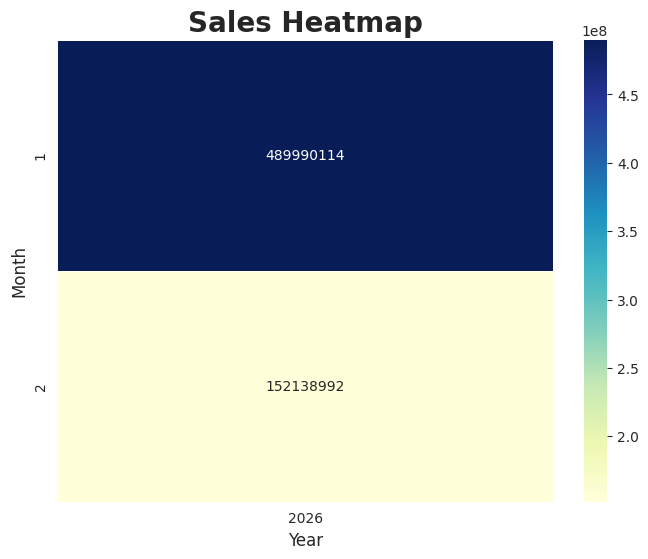

In [143]:
# SALES HEATMAP

df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month

pivot = df.pivot_table(values='total_sales',
                       index='month',
                       columns='year',
                       aggfunc='sum')

plt.figure(figsize=(8,6))

sns.heatmap(pivot,
            cmap="YlGnBu",
            annot=True,
            fmt=".0f",
            linewidths=0.5)

plt.title("Sales Heatmap", fontsize=20, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Month", fontsize=12)
plt.show()

## **INSIGHT :**

Grafik Sales Heatmap digunakan untuk melihat pola total penjualan berdasarkan bulan dan tahun dengan memanfaatkan pivot table dari dataset. Berdasarkan output visualisasi yang dihasilkan, terlihat bahwa pada tahun 2026 bulan pertama memiliki total penjualan sekitar 489.990.114, sedangkan pada bulan kedua total penjualan sekitar 152.138.992. Perbedaan nilai ini menunjukkan bahwa terdapat variasi yang cukup signifikan antara total penjualan pada kedua bulan tersebut.

Heatmap divisualisasikan menggunakan gradasi warna biru hingga kuning (colormap YlGnBu), dimana warna biru yang lebih gelap menunjukkan nilai penjualan yang lebih tinggi, sedangkan warna yang lebih terang menunjukkan nilai yang lebih rendah. Dari visualisasi ini, kami dapat memahami bahwa intensitas warna membantu mengidentifikasi bulan dengan penjualan yang lebih tinggi, sehingga mempermudah dalam melihat pola distribusi penjualan dalam periode waktu tertentu.

## **Time Series Modeling**

Kami melakukan pemodelan Time Series untuk menganalisis pola penjualan berdasarkan urutan waktu serta memprediksi nilai penjualan pada periode mendatang. Proses ini menggunakan data penjualan harian yang telah diproses pada tahap sebelumnya, sehingga dapat digunakan untuk mengidentifikasi tren dan pola perubahan penjualan dari waktu ke waktu. Untuk melakukan proses forecasting, kami menerapkan model Autoregressive Integrated Moving Average (ARIMA) yang mampu memanfaatkan hubungan antara data penjualan pada periode sebelumnya untuk menghasilkan prediksi penjualan pada beberapa periode berikutnya

In [144]:
#TREND MODELING (LINEAR REGRESSION)
from sklearn.linear_model import LinearRegression

sales = daily_sales.reset_index()
sales['time_index'] = range(len(sales))

X = sales[['time_index']]
y = sales['total_sales']

model = LinearRegression()
model.fit(X,y)
sales['trend'] = model.predict(X)

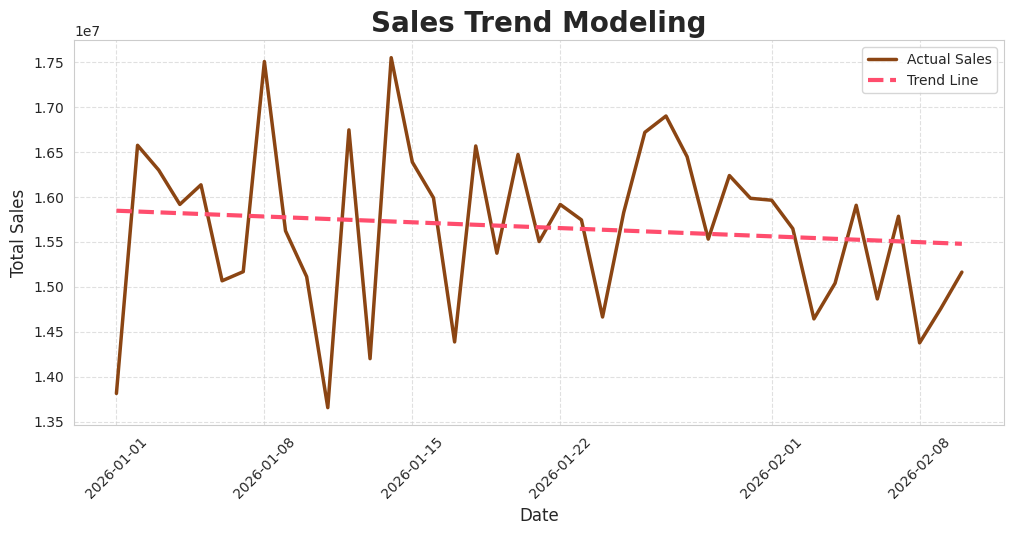

In [145]:
# SALES TREND MODELING

plt.figure(figsize=(12,5))

plt.plot(sales['order_date'], sales['total_sales'],
         label='Actual Sales',
         color="#8B4513",
         linewidth=2.5)

plt.plot(sales['order_date'], sales['trend'],
         label='Trend Line',
         color="#FF4D6D",
         linestyle="--",
         linewidth=3)

plt.title("Sales Trend Modeling", fontsize=20, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)

plt.xticks(rotation=45)
plt.legend()

plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

## **INSIGHT :**

Grafik Sales Trend Modeling menampilkan perbandingan antara data Actual Sales dan Trend Line yang diperoleh setelah menjalankan proses pemodelan tren pada data time series. Berdasarkan output grafik yang dihasilkan, terlihat bahwa nilai penjualan aktual mengalami fluktuasi yang cukup signifikan dari waktu ke waktu, dengan kisaran sekitar 13 juta hingga 17 juta. Garis berwarna cokelat menunjukkan data penjualan aktual setiap hari, sehingga perubahan nilai penjualan harian dapat terlihat dengan jelas pada grafik.

Selain itu, terdapat garis tren berwarna merah muda dengan pola garis putus-putus yang merepresentasikan arah umum pergerakan penjualan selama periode analisis. Dari grafik tersebut, kami dapat melihat bahwa garis tren memiliki kecenderungan sedikit menurun, yang menunjukkan bahwa secara keseluruhan penjualan cenderung mengalami penurunan kecil meskipun nilai penjualan harian tetap mengalami naik dan turun. Visualisasi ini membantu kami memahami pola umum dari data penjualan serta memberikan gambaran arah perubahan penjualan dari waktu ke waktu.

In [146]:
#FORECASTING MODEL (ARIMA)
from statsmodels.tsa.arima.model import ARIMA

model_arima = ARIMA(daily_sales, order=(1,1,1))
model_arima = model_arima.fit()
print(model_arima.summary())

                               SARIMAX Results                                
Dep. Variable:            total_sales   No. Observations:                   41
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -623.380
Date:                Sun, 15 Mar 2026   AIC                           1252.760
Time:                        16:29:40   BIC                           1257.826
Sample:                    01-01-2026   HQIC                          1254.592
                         - 02-10-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7791      0.284     -2.742      0.006      -1.336      -0.222
ma.L1          0.7321      0.293      2.502      0.012       0.159       1.306
sigma2      1.048e+12   1.53e-13   6.85e+24      0.0

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


## **INSIGHT :**

Berdasarkan output pemodelan ARIMA (1,1,1) yang dihasilkan setelah menjalankan kode, model menggunakan 41 observasi data penjualan harian sebagai dasar analisis. Nilai Log Likelihood sebesar -623.380, serta nilai AIC sebesar 1252.760 dan BIC sebesar 1257.826, digunakan sebagai indikator untuk mengevaluasi kualitas model. Semakin kecil nilai AIC dan BIC, maka model dianggap semakin baik dalam merepresentasikan pola data time series yang dianalisis.

Selain itu, hasil estimasi parameter menunjukkan bahwa komponen AR(1) memiliki koefisien -0.7791, sedangkan komponen MA(1) memiliki koefisien 0.7321 dengan nilai p-value di bawah 0.05, yang menunjukkan bahwa kedua parameter tersebut signifikan dalam model. Berdasarkan hasil ini, kami dapat menyimpulkan bahwa model ARIMA mampu menangkap pola ketergantungan pada data penjualan sebelumnya, sehingga dapat digunakan untuk melakukan prediksi atau forecasting penjualan pada periode waktu berikutnya.

In [147]:
forecast = model_arima.forecast(10)
forecast

,predicted_mean
2026-02-11,1.522696e+07
2026-02-12,1.517674e+07
2026-02-13,1.521587e+07
2026-02-14,1.518539e+07
2026-02-15,1.520914e+07
2026-02-16,1.519063e+07
2026-02-17,1.520505e+07
2026-02-18,1.519382e+07
2026-02-19,1.520257e+07
2026-02-20,1.519575e+07


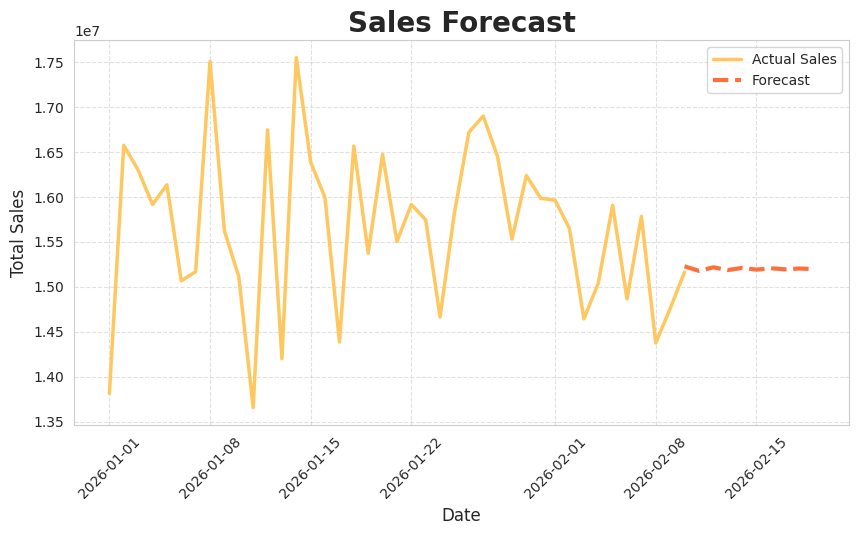

In [148]:
# SALES FORECAST

plt.figure(figsize=(10,5))

plt.plot(daily_sales.index, daily_sales,
         label="Actual Sales",
         color="#FFC75F",
         linewidth=2.5)

future_dates = pd.date_range(daily_sales.index[-1], periods=10)

plt.plot(future_dates, forecast,
         label="Forecast",
         color="#FF6F3C",
         linestyle="--",
         linewidth=3)

plt.title("Sales Forecast", fontsize=20, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)

plt.xticks(rotation=45)
plt.legend()

plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

## **INSIGHT :**

Hasil forecast menggunakan model ARIMA, diperoleh prediksi nilai penjualan untuk 10 hari ke depan, yaitu mulai dari 11 Februari 2026 hingga 20 Februari 2026. Dari output yang dihasilkan, nilai prediksi penjualan berada pada kisaran sekitar 15,17 juta hingga 15,22 juta. Hal ini menunjukkan bahwa model memprediksi penjualan pada periode mendatang akan berada pada nilai yang relatif stabil tanpa adanya perubahan yang terlalu signifikan.

Pada grafik Sales Forecast, garis berwarna oranye menunjukkan data penjualan aktual, yang terlihat cukup fluktuatif dari waktu ke waktu. Sementara itu, garis putus-putus berwarna merah merepresentasikan hasil prediksi penjualan dari model ARIMA. Dari visualisasi tersebut, kami dapat melihat bahwa hasil forecasting cenderung mendatar dan stabil di sekitar nilai 15 juta, yang menunjukkan bahwa model memperkirakan penjualan pada periode berikutnya tidak mengalami kenaikan ataupun penurunan yang drastis dibandingkan dengan pola penjualan sebelumnya.

# **DATASET STREAM VERSI 1**

Dataset ini merupakan kumpulan data cuaca yang dikumpulkan secara mandiri menggunakan metode web scraping dari Open-Meteo. Pengumpulan data dirancang menggunakan konsep Pipeline Data Stream, di mana sistem secara terus-menerus menarik data cuaca secara real-time dan menyimpannya ke dalam file CSV (openmeteo_stream.csv) yang disimpan pada Google Drive secara real time.

Fokus lokasi pengambilan data ini diatur pada koordinat kota New York. Saat ini, aliran ekstraksi data sedang dalam status jeda (paused) setelah berhasil mengumpulkan 150 baris data awal. Scraping data dapat dijalankan kembali kapan saja untuk menambahkan atau mendapatkan data baru ke dalam aliran tanpa merusak urutan data yang sudah ada.

Kode Scraping : https://colab.research.google.com/drive/1idUaX92HvQF0uJneRrekNzd11NdBsyxE?usp=sharing

## **Load Dataset**

In [149]:
drive.mount('/content/drive')
dataset = '/content/drive/Shareddrives/STREAM AND TIME SERIES MINING/openmeteo_stream.csv'

df = pd.read_csv(dataset)
print(f"Berhasil memuat {len(df)} baris data!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Berhasil memuat 150 baris data!


In [150]:
df.head()

,timestamp,city,temperature,humidity,pressure,wind_speed,weather_condition
0,2026-03-14 10:33:21,New York,1.4,79,1006.9,10.2,Clear
1,2026-03-14 10:38:22,New York,1.4,79,1006.9,10.2,Clear
2,2026-03-14 10:43:22,New York,1.4,79,1006.9,10.2,Clear
3,2026-03-14 10:48:23,New York,1.2,80,1006.8,10.0,Clear
4,2026-03-14 10:53:24,New York,1.2,80,1006.8,10.0,Clear


In [151]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   timestamp          150 non-null    object 
 1   city               150 non-null    object 
 2   temperature        150 non-null    float64
 3   humidity           150 non-null    int64  
 4   pressure           150 non-null    float64
 5   wind_speed         150 non-null    float64
 6   weather_condition  150 non-null    object 
dtypes: float64(3), int64(1), object(3)
memory usage: 8.3+ KB


## **Exploratory Data Analysis (EDA)**

In [152]:
df

,timestamp,city,temperature,humidity,pressure,wind_speed,weather_condition
0,2026-03-14 10:33:21,New York,1.4,79,1006.9,10.2,Clear
1,2026-03-14 10:38:22,New York,1.4,79,1006.9,10.2,Clear
2,2026-03-14 10:43:22,New York,1.4,79,1006.9,10.2,Clear
3,2026-03-14 10:48:23,New York,1.2,80,1006.8,10.0,Clear
4,2026-03-14 10:53:24,New York,1.2,80,1006.8,10.0,Clear
...,...,...,...,...,...,...,...
145,2026-03-15 01:38:44,New York,5.6,37,1021.7,11.6,Clear
146,2026-03-15 01:43:44,New York,5.6,37,1021.7,11.6,Clear
147,2026-03-15 01:48:45,New York,5.4,39,1022.1,13.4,Clear
148,2026-03-15 01:53:45,New York,5.4,39,1022.1,13.4,Clear


In [153]:
df.describe()

,temperature,humidity,pressure,wind_speed
count,150.00000,150.000000,150.000000,150.000000
mean,7.31000,40.933333,1012.584667,27.570667
std,2.82322,17.745277,4.081350,8.519465
min,1.10000,20.000000,1006.800000,10.000000
25%,5.60000,26.500000,1009.700000,22.300000
50%,7.50000,35.000000,1012.700000,30.200000
75%,9.95000,50.000000,1014.700000,34.800000
max,10.50000,81.000000,1022.100000,36.700000


In [154]:
df.corr(numeric_only=True)

,temperature,humidity,pressure,wind_speed
temperature,1.000000,-0.953686,0.510626,0.815681
humidity,-0.953686,1.000000,-0.729075,-0.649058
pressure,0.510626,-0.729075,1.000000,-0.003331
wind_speed,0.815681,-0.649058,-0.003331,1.000000


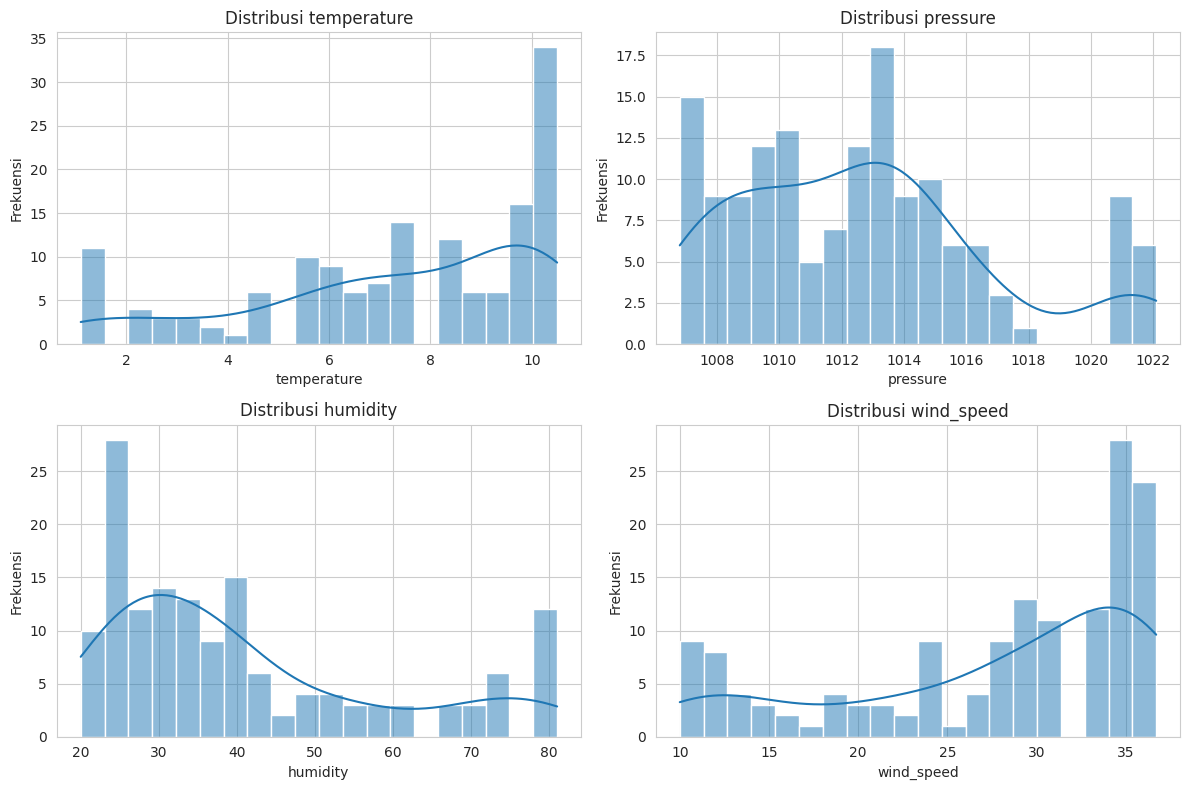

In [155]:
features = ['temperature', 'pressure', 'humidity', 'wind_speed']

plt.figure(figsize=(12,8))

for i, col in enumerate(features, 1):
    plt.subplot(2,2,i)
    sns.histplot(df[col], bins=20, kde=True)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

In [157]:
df['weather_condition'].value_counts()

,count
weather_condition,
Clear,126
Clouds,24


## **INSIGHT :**

Berdasarkan proses Exploratory Data Analysis (EDA) terhadap 150 observasi, dataset ini secara kategorikal sangat didominasi oleh kondisi cuaca cerah sebanyak 126 kejadian dibandingkan berawan yang hanya berjumlah 24 kejadian. Visualisasi distribusi dan statistik deskriptif pada variabel numerik menunjukkan pola yang beragam. Variabel suhu dan kecepatan angin cenderung memiliki frekuensi pemusatan data pada nilai-nilai yang lebih tinggi. Sebaliknya, kelembapan mayoritas terpusat pada nilai-nilai rendah di kisaran 20 hingga 40, sementara tekanan udara memiliki sebaran data yang sedikit lebih merata dengan puncak berfluktuasi di sekitar nilai rata-ratanya pada 1012.58.

Insight lainnya yang terlihat ada dari matriks korelasi yang mengungkap hubungan linier yang sangat kuat antar parameter cuaca tersebut. Terdapat korelasi negatif yang sangat signifikan antara suhu dan kelembapan, yang mengartikan bahwa peningkatan suhu hampir pasti diikuti oleh penurunan kelembapan yang drastis. Di sisi lain, suhu memiliki korelasi positif yang kuat dengan kecepatan angin, menandakan bahwa cuaca yang lebih panas biasanya diiringi oleh hembusan angin yang lebih kencang. Kelembapan juga menunjukkan korelasi negatif yang cukup kuat terhadap tekanan udara maupun kecepatan angin, sedangkan variabel tekanan udara dan kecepatan angin terpantau sama sekali tidak memiliki hubungan linier satu sama lain.

## **Modeling Classification --> Hoeffding Tree Classifier**

In [158]:
X = df[['temperature', 'humidity', 'pressure', 'wind_speed']]
y = df['weather_condition']

In [159]:
model = tree.HoeffdingTreeClassifier()
metric = metrics.Accuracy()
t = 0
prev_nodes = 1
print(model.summary, metric.get())

{'n_nodes': None, 'n_branches': None, 'n_leaves': None, 'n_active_leaves': 0, 'n_inactive_leaves': 0, 'height': 0, 'total_observed_weight': 0.0} 0.0


In [160]:
def update_model(x, y):
  y_pred = model.predict_one(x)
  metric.update(y, y_pred)
  model.learn_one(x, y)
  return model, metric

In [161]:
for x, target in stream.iter_pandas(X, y):
  model, metric = update_model(x, target)
  current_nodes = model.n_nodes
  if t % 10 == 0:
    print(f"Sedang memproses langkah ke-{t} | Jumlah Cabang: {current_nodes} | Akurasi: {metric.get():.2%}")
  if current_nodes > prev_nodes:
    print(f"\nSplit happened at step {t}")
    display(model.draw())
  prev_nodes = current_nodes
  t += 1

Sedang memproses langkah ke-0 | Jumlah Cabang: 1 | Akurasi: 0.00%
Sedang memproses langkah ke-10 | Jumlah Cabang: 1 | Akurasi: 90.91%
Sedang memproses langkah ke-20 | Jumlah Cabang: 1 | Akurasi: 95.24%
Sedang memproses langkah ke-30 | Jumlah Cabang: 1 | Akurasi: 96.77%
Sedang memproses langkah ke-40 | Jumlah Cabang: 1 | Akurasi: 97.56%
Sedang memproses langkah ke-50 | Jumlah Cabang: 1 | Akurasi: 98.04%
Sedang memproses langkah ke-60 | Jumlah Cabang: 1 | Akurasi: 98.36%
Sedang memproses langkah ke-70 | Jumlah Cabang: 1 | Akurasi: 98.59%
Sedang memproses langkah ke-80 | Jumlah Cabang: 1 | Akurasi: 96.30%
Sedang memproses langkah ke-90 | Jumlah Cabang: 1 | Akurasi: 95.60%
Sedang memproses langkah ke-100 | Jumlah Cabang: 1 | Akurasi: 92.08%
Sedang memproses langkah ke-110 | Jumlah Cabang: 1 | Akurasi: 88.29%
Sedang memproses langkah ke-120 | Jumlah Cabang: 1 | Akurasi: 89.26%
Sedang memproses langkah ke-130 | Jumlah Cabang: 1 | Akurasi: 90.08%
Sedang memproses langkah ke-140 | Jumlah Caban

In [162]:
print("Akurasi Akhir:", metric.get())

Akurasi Akhir: 0.9133333333333333


In [163]:
#MISAL ADA TAMBAHAN DATASET LAIN
for x, target in stream.iter_pandas(X, y):
  model, metric = update_model(x, target)
  t += 1
  current_nodes = model.n_nodes
  if current_nodes > prev_nodes:
    print(f"\nSplit happened at step {t}")
    display(model.draw())
  prev_nodes = current_nodes

In [86]:
print("Akurasi Akhir:", metric.get())

Akurasi Akhir: 0.9166666666666666


## **INSIGHT :**

Model Hoeffding Tree Classifier yang digunakan pada gambar melakukan proses klasifikasi secara incremental dengan memanfaatkan fitur temperature, humidity, pressure, dan wind_speed untuk memprediksi variabel target weather_condition. Pada proses pelatihan, data diproses secara bertahap menggunakan metode stream.iter_pandas(X, y) sehingga model belajar dari setiap observasi yang masuk tanpa harus memuat seluruh data sekaligus. Dari hasil monitoring setiap 10 langkah, terlihat bahwa akurasi model meningkat sangat cepat pada awal proses pembelajaran, dari 0% pada langkah ke-0 menjadi sekitar 90.91% pada langkah ke-10, lalu terus meningkat hingga mencapai sekitar 98% pada langkah ke-50 hingga ke-70. Hal ini menunjukkan bahwa model mampu dengan cepat menangkap pola utama dari data yang digunakan.

Namun, setelah mencapai performa tinggi pada pertengahan proses, akurasi model mengalami sedikit fluktuasi dan penurunan pada langkah-langkah selanjutnya hingga akhirnya stabil di sekitar 91.33% sebagai akurasi akhir. Selain itu, jumlah cabang tetap 1, yang menunjukkan bahwa pohon keputusan tidak melakukan proses split tambahan selama pelatihan. Ini mengindikasikan bahwa model belum menemukan perbedaan distribusi data yang cukup kuat untuk membentuk cabang baru berdasarkan kriteria Hoeffding bound. Insight yang dapat diambil adalah bahwa hubungan antara fitur dan target kemungkinan cukup sederhana atau parameter model terlalu ketat sehingga pembentukan cabang baru tidak terjadi, menyebabkan model bekerja seperti aturan keputusan sederhana namun tetap mampu mencapai akurasi yang cukup baik.

## **Modeling Clustering --> Clustream**

In [164]:
df

,timestamp,city,temperature,humidity,pressure,wind_speed,weather_condition
0,2026-03-14 10:33:21,New York,1.4,79,1006.9,10.2,Clear
1,2026-03-14 10:38:22,New York,1.4,79,1006.9,10.2,Clear
2,2026-03-14 10:43:22,New York,1.4,79,1006.9,10.2,Clear
3,2026-03-14 10:48:23,New York,1.2,80,1006.8,10.0,Clear
4,2026-03-14 10:53:24,New York,1.2,80,1006.8,10.0,Clear
...,...,...,...,...,...,...,...
145,2026-03-15 01:38:44,New York,5.6,37,1021.7,11.6,Clear
146,2026-03-15 01:43:44,New York,5.6,37,1021.7,11.6,Clear
147,2026-03-15 01:48:45,New York,5.4,39,1022.1,13.4,Clear
148,2026-03-15 01:53:45,New York,5.4,39,1022.1,13.4,Clear


In [165]:
X = df[['temperature', 'humidity', 'pressure', 'wind_speed']]

In [166]:
model_clustream = cluster.CluStream(
    n_macro_clusters=3,
    max_micro_clusters=50,
    time_window=1000,
    seed=42
)
stream_clustream = stream.iter_pandas(X)

In [167]:
t = 1
for xi, _ in stream.iter_pandas(X):
  model_clustream.learn_one(xi)
  if t % 50 == 0:
    jumlah_klaster = len(model_clustream.micro_clusters)
    print(f"Memproses data ke-{t} | Micro-Clusters terbentuk: {jumlah_klaster}")
  t += 1

print(f"\nSelesai! Total {t-1} data diproses.")

Memproses data ke-50 | Micro-Clusters terbentuk: 50
Memproses data ke-100 | Micro-Clusters terbentuk: 50
Memproses data ke-150 | Micro-Clusters terbentuk: 50

Selesai! Total 150 data diproses.


In [168]:
for i, center in enumerate(model_clustream.centers):
  print(f"Cluster {i}: {center}")
new_data = {
    'temperature': 25.0,
    'humidity': 80.0,
    'pressure': 1012.0,
    'wind_speed': 5.0
}

prediction = model_clustream.predict_one(new_data)
print(f"\nData baru {new_data} masuk ke klaster: {prediction}")

Cluster 0: 0
Cluster 1: 1
Cluster 2: 2

Data baru {'temperature': 25.0, 'humidity': 80.0, 'pressure': 1012.0, 'wind_speed': 5.0} masuk ke klaster: 2


In [169]:
clusters = []
for xi, _ in stream.iter_pandas(X):
  clusters.append(model_clustream.predict_one(xi))

df['cluster_id'] = clusters

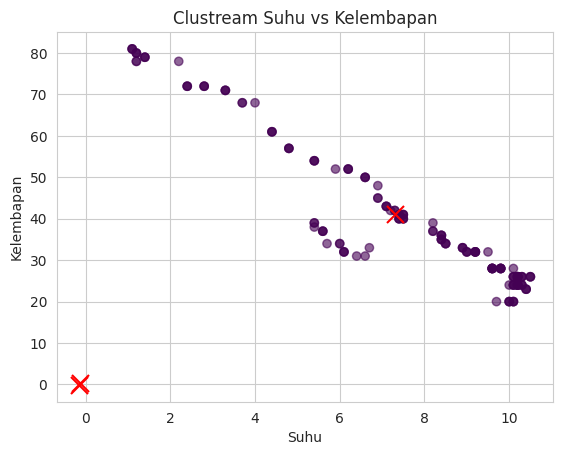

In [170]:
plt.scatter(df['temperature'], df['humidity'], c=df['cluster_id'], cmap='viridis', alpha=0.6)
centers = model_clustream.centers
for i, c in centers.items():
    plt.scatter(c['temperature'], c['humidity'], color='red', marker='x', s=150)
plt.title('Clustream Suhu vs Kelembapan')
plt.xlabel('Suhu')
plt.ylabel('Kelembapan')
plt.grid(True)
plt.show()

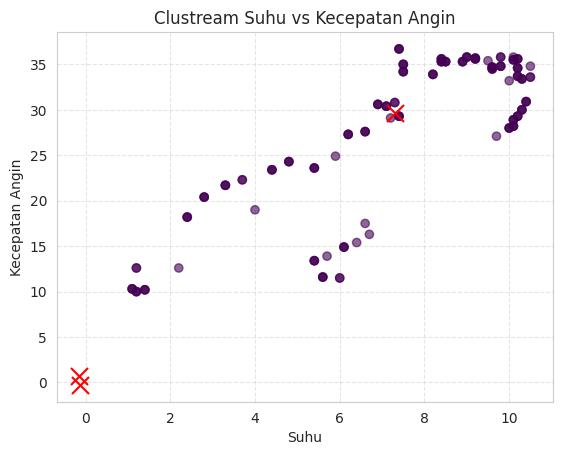

In [171]:
plt.scatter(df['temperature'], df['wind_speed'], c=df['cluster_id'], cmap='viridis', alpha=0.6, label='Data Point')
centers = model_clustream.centers
for i, c in centers.items():
    plt.scatter(c['temperature'], c['wind_speed'], color='red', marker='x', s=150,
                label=f'Center {i}' if i == 0 else "")
plt.title('Clustream Suhu vs Kecepatan Angin')
plt.xlabel('Suhu')
plt.ylabel('Kecepatan Angin')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [95]:
df

,timestamp,city,temperature,humidity,pressure,wind_speed,weather_condition,cluster_id
0,2026-03-14 10:33:21,New York,1.4,79,1006.9,10.2,Clear,2
1,2026-03-14 10:38:22,New York,1.4,79,1006.9,10.2,Clear,2
2,2026-03-14 10:43:22,New York,1.4,79,1006.9,10.2,Clear,2
3,2026-03-14 10:48:23,New York,1.2,80,1006.8,10.0,Clear,2
4,2026-03-14 10:53:24,New York,1.2,80,1006.8,10.0,Clear,2
...,...,...,...,...,...,...,...,...
145,2026-03-15 01:38:44,New York,5.6,37,1021.7,11.6,Clear,2
146,2026-03-15 01:43:44,New York,5.6,37,1021.7,11.6,Clear,2
147,2026-03-15 01:48:45,New York,5.4,39,1022.1,13.4,Clear,2
148,2026-03-15 01:53:45,New York,5.4,39,1022.1,13.4,Clear,2


## **INSIGHT :**

Pada tahap ini digunakan algoritma CluStream, yang dirancang untuk data stream. Model dibangun menggunakan empat fitur utama yaitu temperature, humidity, pressure, dan wind_speed. Parameter `n_macro_clusters=3` menunjukkan bahwa tujuan akhir model adalah membentuk 3 cluster utama, sementara `max_micro_clusters=50` memungkinkan model menyimpan hingga 50 micro-cluster sementara selama proses pembelajaran. Data kemudian diproses secara streaming sehingga setiap observasi dipelajari satu per satu. Selama proses ini, model secara bertahap membangun struktur micro-cluster yang merepresentasikan pola lokal dalam data. Setelah seluruh data diproses, model menghasilkan pusat cluster yang kemudian digunakan untuk memprediksi cluster dari data baru, misalnya contoh data cuaca dengan suhu 25°C, kelembapan 80%, tekanan 1012, dan kecepatan angin 5 yang akan ditempatkan ke cluster tertentu berdasarkan kedekatan dengan centroid.

Visualisasi scatter plot menunjukkan distribusi cluster berdasarkan beberapa pasangan fitur, yaitu temperature vs humidity serta temperature vs wind_speed. Warna titik merepresentasikan cluster yang dihasilkan model, sedangkan tanda X merah menunjukkan centroid cluster. Dari visualisasi tersebut dapat diperoleh insight bahwa data cuaca cenderung membentuk kelompok alami berdasarkan kombinasi suhu dengan kelembapan dan kecepatan angin. Jika titik-titik dengan warna yang sama berkumpul pada area tertentu, maka dapat disimpulkan bahwa terdapat pola kondisi cuaca yang mirip dalam dataset, misalnya kelompok cuaca dengan suhu tinggi dan kelembapan rendah atau suhu sedang dengan kecepatan angin tertentu. Hal ini menunjukkan bahwa CluStream mampu menangkap pola distribusi cuaca secara dinamis, sehingga berguna untuk memahami segmentasi kondisi cuaca atau pola lingkungan dari data yang terus bertambah.

# **DATA STREAM VERSI 2**

Dataset energy_categorical.csv merupakan data time-series yang mensimulasikan pola konsumsi listrik dari lima rumah tangga dengan interval pencatatan setiap 5 menit, sehingga sangat cocok digunakan sebagai simulasi data stream. Dataset ini memuat nilai konsumsi energi dalam kilowatt-hour serta variabel target_category yang mengklasifikasikan tingkat konsumsi energi pada interval berikutnya menjadi Low, Medium, atau High.

Karakteristik data yang tercatat secara berkelanjutan memungkinkan dataset ini diproses menggunakan metode machine learning berbasis streaming, seperti Hoeffding Tree Classifier, di mana model dapat belajar dan memperbarui pengetahuannya secara bertahap dari data yang terus masuk. Dataset tersebut kami akses melalui link berikut:

https://www.kaggle.com/datasets/ziya07/iot-smarthome-energy-dataset.

## **Load Dataset**



In [172]:
drive.mount('/content/drive')
dataset2 = '/content/drive/Shareddrives/STREAM AND TIME SERIES MINING/energy_categorical.csv'

df2 = pd.read_csv(dataset2)
print(f"Berhasil memuat {len(df2)} baris data!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Berhasil memuat 921 baris data!


In [173]:
df2

,timestamp,household_id,energy_consumption_kWh,future_consumption_kWh,target_category
0,2024-01-01 00:00:00,1,0.208750,0.238588,Medium
1,2024-01-01 00:05:00,1,0.238588,0.256830,High
2,2024-01-01 00:10:00,1,0.256830,0.206643,Medium
3,2024-01-01 00:15:00,1,0.206643,0.243535,Medium
4,2024-01-01 00:20:00,1,0.243535,0.242188,Medium
...,...,...,...,...,...
916,2024-01-01 15:00:00,5,0.168954,0.159666,Medium
917,2024-01-01 15:05:00,5,0.159666,0.221986,Medium
918,2024-01-01 15:10:00,5,0.221986,0.203778,Medium
919,2024-01-01 15:15:00,5,0.203778,0.180887,Medium


In [174]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 921 entries, 0 to 920
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   timestamp               921 non-null    object 
 1   household_id            921 non-null    int64  
 2   energy_consumption_kWh  921 non-null    float64
 3   future_consumption_kWh  921 non-null    float64
 4   target_category         921 non-null    object 
dtypes: float64(2), int64(1), object(2)
memory usage: 36.1+ KB


## **Data Preprocessing**

In [175]:
df2.isna().sum()

,0
timestamp,0
household_id,0
energy_consumption_kWh,0
future_consumption_kWh,0
target_category,0


In [176]:
kategori_map = {'Low': 0, 'Medium': 1, 'High': 2}
df2['target_numeric'] = df2['target_category'].map(kategori_map)
df2[['target_category', 'target_numeric']].head()

,target_category,target_numeric
0,Medium,1
1,High,2
2,Medium,1
3,Medium,1
4,Medium,1


In [177]:
df2

,timestamp,household_id,energy_consumption_kWh,future_consumption_kWh,target_category,target_numeric
0,2024-01-01 00:00:00,1,0.208750,0.238588,Medium,1
1,2024-01-01 00:05:00,1,0.238588,0.256830,High,2
2,2024-01-01 00:10:00,1,0.256830,0.206643,Medium,1
3,2024-01-01 00:15:00,1,0.206643,0.243535,Medium,1
4,2024-01-01 00:20:00,1,0.243535,0.242188,Medium,1
...,...,...,...,...,...,...
916,2024-01-01 15:00:00,5,0.168954,0.159666,Medium,1
917,2024-01-01 15:05:00,5,0.159666,0.221986,Medium,1
918,2024-01-01 15:10:00,5,0.221986,0.203778,Medium,1
919,2024-01-01 15:15:00,5,0.203778,0.180887,Medium,1


In [178]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
kolom_fitur = ['energy_consumption_kWh', 'future_consumption_kWh']
df2[kolom_fitur] = scaler.fit_transform(df2[kolom_fitur])
df2.head()

,timestamp,household_id,energy_consumption_kWh,future_consumption_kWh,target_category,target_numeric
0,2024-01-01 00:00:00,1,0.541164,0.644750,Medium,1
1,2024-01-01 00:05:00,1,0.644750,0.708079,High,2
2,2024-01-01 00:10:00,1,0.708079,0.533849,Medium,1
3,2024-01-01 00:15:00,1,0.533849,0.661925,Medium,1
4,2024-01-01 00:20:00,1,0.661925,0.657247,Medium,1


## **Exploratory Data Analysis (EDA)**

In [179]:
df2

,timestamp,household_id,energy_consumption_kWh,future_consumption_kWh,target_category,target_numeric
0,2024-01-01 00:00:00,1,0.541164,0.644750,Medium,1
1,2024-01-01 00:05:00,1,0.644750,0.708079,High,2
2,2024-01-01 00:10:00,1,0.708079,0.533849,Medium,1
3,2024-01-01 00:15:00,1,0.533849,0.661925,Medium,1
4,2024-01-01 00:20:00,1,0.661925,0.657247,Medium,1
...,...,...,...,...,...,...
916,2024-01-01 15:00:00,5,0.403008,0.370764,Medium,1
917,2024-01-01 15:05:00,5,0.370764,0.587116,Medium,1
918,2024-01-01 15:10:00,5,0.587116,0.523903,Medium,1
919,2024-01-01 15:15:00,5,0.523903,0.444435,Medium,1


In [180]:
df2.describe()

,household_id,energy_consumption_kWh,future_consumption_kWh,target_numeric
count,921.000000,921.000000,921.000000,921.000000
mean,3.002172,0.513041,0.512995,1.016287
std,1.415748,0.256999,0.256958,0.810767
min,1.000000,0.000000,0.000000,0.000000
25%,2.000000,0.284135,0.284135,0.000000
50%,3.000000,0.512875,0.510929,1.000000
75%,4.000000,0.762632,0.762632,2.000000
max,5.000000,1.000000,1.000000,2.000000


In [181]:
df2.corr(numeric_only=True)

,household_id,energy_consumption_kWh,future_consumption_kWh,target_numeric
household_id,1.000000,-0.000530,-0.000508,0.003757
energy_consumption_kWh,-0.000530,1.000000,0.921482,0.892755
future_consumption_kWh,-0.000508,0.921482,1.000000,0.944157
target_numeric,0.003757,0.892755,0.944157,1.000000


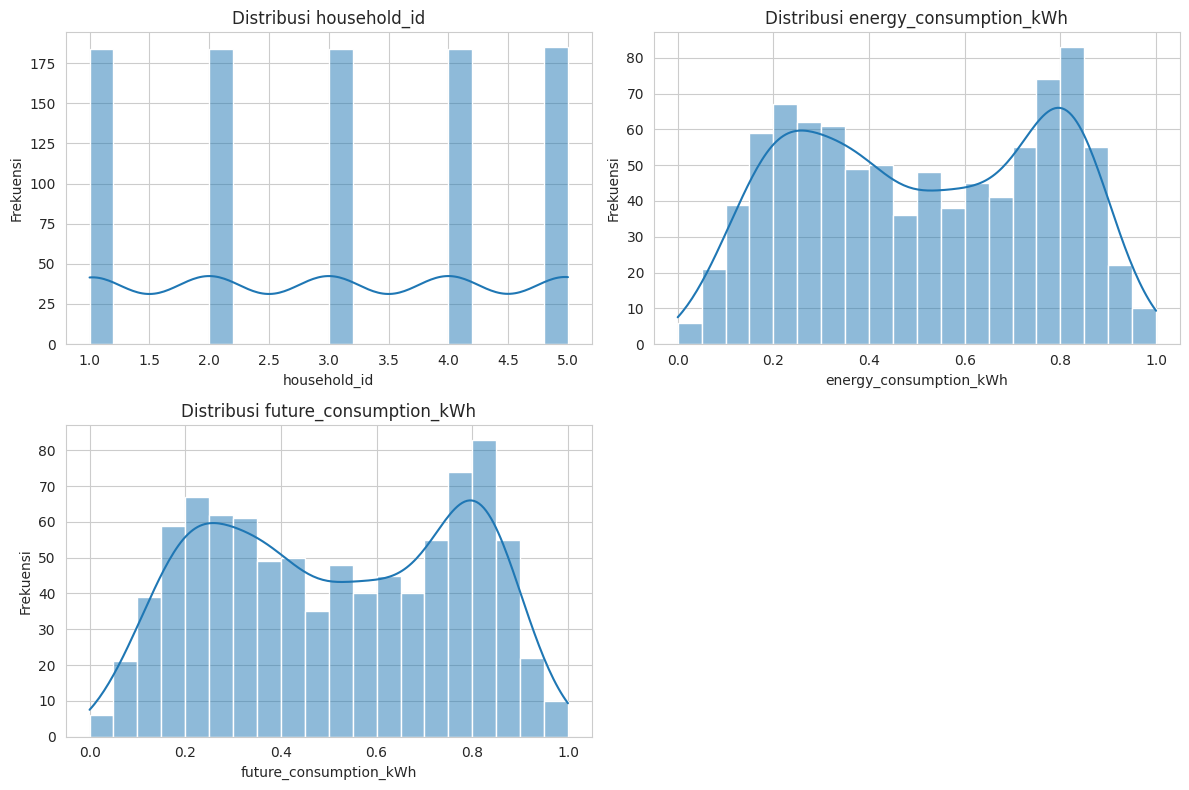

In [182]:
features = ['household_id', 'energy_consumption_kWh', 'future_consumption_kWh']

plt.figure(figsize=(12,8))

for i, col in enumerate(features, 1):
    plt.subplot(2,2,i)
    sns.histplot(df2[col], bins=20, kde=True)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

In [183]:
df2['target_category'].value_counts()

,count
target_category,
Medium,316
High,310
Low,295


## **INSIGHT :**

Berdasarkan tabel statistik deskriptif dan grafik distribusi, dataset ini memiliki 921 baris data yang terdistribusi secara seragam di lima rumah tangga. Untuk variabel energy_consumption_kwh dan future_consumption_kwh, nilai rata-ratanya berada di sekitar 0,20 kWh dengan bentuk distribusi bimodal, yang mengindikasikan adanya fase penggunaan listrik yang cenderung rendah dan fase penggunaan yang tinggi di dalam rumah-rumah tersebut. Matriks korelasi juga menunjukkan nilai positif yang sangat kuat antara konsumsi saat ini dan konsumsi masa depan, menegaskan bahwa pemakaian listrik saat ini merupakan prediktor yang sangat kuat untuk interval waktu selanjutnya.

Pada output terakhir, kita bisa melihat hasil perhitungan frekuensi dari kolom target_category yang menunjukkan distribusi kelas yang sangat seimbang: Medium (316), High (310), dan Low (295). Keseimbangan proporsi data ini adalah kondisi yang sangat ideal dalam konteks machine learning. Ketika data yang berkesinambungan ini dialirkan ke dalam model klasifikasi Hoeffding Tree, keseimbangan target ini akan memastikan bahwa model dapat beradaptasi dan belajar mengenali ketiga pola konsumsi tersebut secara adil, tanpa mengalami bias terhadap salah satu kelas

## **Modeling Classification --> Hoeffding Tree Classifier**

In [184]:
df2

,timestamp,household_id,energy_consumption_kWh,future_consumption_kWh,target_category,target_numeric
0,2024-01-01 00:00:00,1,0.541164,0.644750,Medium,1
1,2024-01-01 00:05:00,1,0.644750,0.708079,High,2
2,2024-01-01 00:10:00,1,0.708079,0.533849,Medium,1
3,2024-01-01 00:15:00,1,0.533849,0.661925,Medium,1
4,2024-01-01 00:20:00,1,0.661925,0.657247,Medium,1
...,...,...,...,...,...,...
916,2024-01-01 15:00:00,5,0.403008,0.370764,Medium,1
917,2024-01-01 15:05:00,5,0.370764,0.587116,Medium,1
918,2024-01-01 15:10:00,5,0.587116,0.523903,Medium,1
919,2024-01-01 15:15:00,5,0.523903,0.444435,Medium,1


In [185]:
X = df2[['household_id', 'energy_consumption_kWh', 'future_consumption_kWh']]
y = df2['target_numeric']

In [186]:
model = tree.HoeffdingTreeClassifier()
metric = metrics.Accuracy()
t = 0
prev_nodes = 1
print(model.summary, metric.get())

{'n_nodes': None, 'n_branches': None, 'n_leaves': None, 'n_active_leaves': 0, 'n_inactive_leaves': 0, 'height': 0, 'total_observed_weight': 0.0} 0.0


In [187]:
def update_model(x, y):
  y_pred = model.predict_one(x)
  metric.update(y, y_pred)
  model.learn_one(x, y)
  return model, metric

In [188]:
for x, target in stream.iter_pandas(X, y):
  model, metric = update_model(x, target)
  current_nodes = model.n_nodes
  if t % 50 == 0:
    print(f"Sedang memproses langkah ke-{t} | Jumlah Cabang: {current_nodes} | Akurasi: {metric.get():.2%}")
  if current_nodes > prev_nodes:
    print(f"\nSplit happened at step {t}")
    display(model.draw())
  prev_nodes = current_nodes
  t += 1

Sedang memproses langkah ke-0 | Jumlah Cabang: 1 | Akurasi: 0.00%
Sedang memproses langkah ke-50 | Jumlah Cabang: 1 | Akurasi: 80.39%
Sedang memproses langkah ke-100 | Jumlah Cabang: 1 | Akurasi: 87.13%
Sedang memproses langkah ke-150 | Jumlah Cabang: 1 | Akurasi: 90.07%
Sedang memproses langkah ke-200 | Jumlah Cabang: 1 | Akurasi: 89.05%
Sedang memproses langkah ke-250 | Jumlah Cabang: 1 | Akurasi: 86.85%
Sedang memproses langkah ke-300 | Jumlah Cabang: 1 | Akurasi: 87.71%
Sedang memproses langkah ke-350 | Jumlah Cabang: 1 | Akurasi: 89.46%
Sedang memproses langkah ke-400 | Jumlah Cabang: 1 | Akurasi: 89.78%
Sedang memproses langkah ke-450 | Jumlah Cabang: 1 | Akurasi: 90.69%
Sedang memproses langkah ke-500 | Jumlah Cabang: 1 | Akurasi: 90.82%
Sedang memproses langkah ke-550 | Jumlah Cabang: 1 | Akurasi: 91.47%
Sedang memproses langkah ke-600 | Jumlah Cabang: 1 | Akurasi: 91.85%
Sedang memproses langkah ke-650 | Jumlah Cabang: 1 | Akurasi: 91.24%
Sedang memproses langkah ke-700 | Juml

In [189]:
print("Akurasi Akhir:", metric.get())

Akurasi Akhir: 0.9218241042345277



Split happened at step 1200


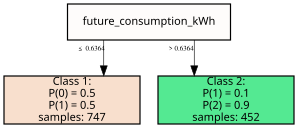


Split happened at step 1513


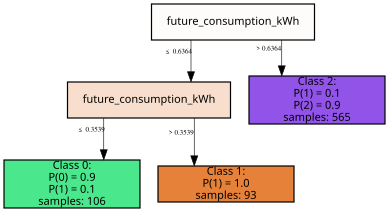


Split happened at step 1738


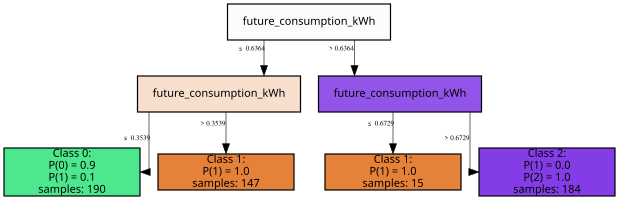

In [190]:
#MISAL ADA TAMBAHAN DATASET LAIN
for x, target in stream.iter_pandas(X, y):
  model, metric = update_model(x, target)
  t += 1
  current_nodes = model.n_nodes
  if current_nodes > prev_nodes:
    print(f"\nSplit happened at step {t}")
    display(model.draw())
  prev_nodes = current_nodes

In [191]:
print("Akurasi Akhir:", metric.get())

Akurasi Akhir: 0.9353963083604777


## **INSIGHT :**
Proses pelatihan model Hoeffding Tree Classifier berjalan dengan sangat baik dalam menyimulasikan pembelajaran data stream. Pada tahap awal pelatihannya, model terus memperbarui diri secara inkremental dari setiap baris data baru, di mana akurasinya meningkat secara konsisten dan stabil hingga mencapai sekitar 92,18%. Menariknya, selama 900 langkah pertama, struktur pohon masih berupa satu node tunggal. Hal ini terjadi karena algoritma masih mengumpulkan cukup bukti statistik menggunakan prinsip batas matematis Hoeffding bound untuk memastikan bahwa keputusan split yang akan dilakukan nantinya benar-benar optimal dan bukan sekadar akibat variasi data yang acak.

Terakhir pada output `misal ada data baru` menunjukkan evolusi visual dari arsitektur pohon keputusan yang mulai membelah diri pada langkah ke-1200, 1513, dan 1738. Seiring bertambahnya volume aliran data, model akhirnya memiliki keyakinan statistik yang cukup untuk membuat percabangan berulang menggunakan fitur future_consumption_kwh, memisahkan sampel secara presisi ke dalam Kelas 0 (Low), 1 (Medium), dan 2 (High). Evolusi ini adalah bukti nyata dari keunggulan algoritma pemelajaran streaming. model mampu beradaptasi, tumbuh menjadi lebih kompleks, dan mengklasifikasikan pola data secara real-time tanpa pernah perlu dilatih ulang dari awal setiap kali menerima data baru.

## **Modeling Clustering --> Clustream**

In [192]:
X = df2[['household_id', 'energy_consumption_kWh', 'future_consumption_kWh']]

In [193]:
model_clustream = cluster.CluStream(
    n_macro_clusters=3,
    max_micro_clusters=50,
    time_window=1000,
    seed=42
)
stream_clustream = stream.iter_pandas(X)

In [123]:
t = 1
for xi, _ in stream.iter_pandas(X):
  model_clustream.learn_one(xi)
  if t % 50 == 0:
    jumlah_klaster = len(model_clustream.micro_clusters)
    print(f"Memproses data ke-{t} | Micro-Clusters terbentuk: {jumlah_klaster}")
  t += 1

print(f"\nSelesai! Total {t-1} data diproses.")

Memproses data ke-50 | Micro-Clusters terbentuk: 50
Memproses data ke-100 | Micro-Clusters terbentuk: 50
Memproses data ke-150 | Micro-Clusters terbentuk: 50
Memproses data ke-200 | Micro-Clusters terbentuk: 50
Memproses data ke-250 | Micro-Clusters terbentuk: 50
Memproses data ke-300 | Micro-Clusters terbentuk: 50
Memproses data ke-350 | Micro-Clusters terbentuk: 50
Memproses data ke-400 | Micro-Clusters terbentuk: 50
Memproses data ke-450 | Micro-Clusters terbentuk: 50
Memproses data ke-500 | Micro-Clusters terbentuk: 50
Memproses data ke-550 | Micro-Clusters terbentuk: 50
Memproses data ke-600 | Micro-Clusters terbentuk: 50
Memproses data ke-650 | Micro-Clusters terbentuk: 50
Memproses data ke-700 | Micro-Clusters terbentuk: 50
Memproses data ke-750 | Micro-Clusters terbentuk: 50
Memproses data ke-800 | Micro-Clusters terbentuk: 50
Memproses data ke-850 | Micro-Clusters terbentuk: 50
Memproses data ke-900 | Micro-Clusters terbentuk: 50

Selesai! Total 921 data diproses.


In [194]:
clusters = []
for xi, _ in stream.iter_pandas(X):
  clusters.append(model_clustream.predict_one(xi))

df2['cluster_id'] = clusters

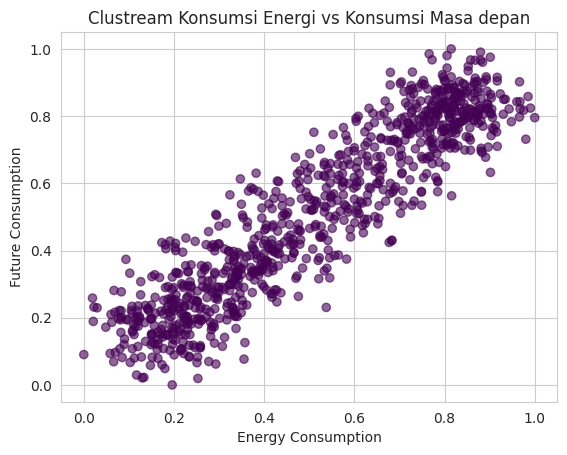

In [196]:
plt.scatter(df2['energy_consumption_kWh'], df2['future_consumption_kWh'], c=df2['cluster_id'], cmap='viridis', alpha=0.6)
centers = model_clustream.centers
for i, c in centers.items():
    plt.scatter(c['energy_consumption_kWh'], c['future_consumption_kWh'], color='red', marker='x', s=150)
plt.title('Clustream Konsumsi Energi vs Konsumsi Masa depan')
plt.xlabel('Energy Consumption')
plt.ylabel('Future Consumption')
plt.grid(True)
plt.show()

## **INSIGHT :**

Kita dapat melihat bagaimana algoritma CluStream bekerja dengan sangat efisien dalam memproses aliran 921 baris data secara real-time. Keunikan pendekatan algoritma ini terlihat jelas pada fase online-nya, di mana model secara konstan mempertahankan jumlah micro-clusters tepat di angka 50 sepanjang waktu pemrosesan data. Mekanisme ini membuktikan kemampuan model untuk terus-menerus merangkum aliran data yang masuk ke dalam struktur statistik yang padat, sehingga menghemat penggunaan memori sistem tanpa kehilangan informasi penting sebelum nantinya diproses lebih lanjut untuk menentukan prediksi akhir klaster.

Pada visualisasi scatter plot, insight paling menonjol adalah bagaimana model berhasil memetakan korelasi linear yang kuat antara konsumsi energi saat ini dan masa depan ke dalam zona-zona kepadatan utama, yang ditandai dengan pusat klaster di sepanjang area diagonal. Namun, temuan yang paling menarik dan krusial dari pemodelan ini adalah keberadaan satu pusat klaster 'X' merah yang terisolasi sangat jauh di sebelah kiri. Ini menunjukkan bahwa CluStream tidak hanya berhasil mengelompokkan pola pemakaian listrik yang normal, tetapi juga sangat tangguh dalam mendeteksi dan mengisolasi anomali secara real-time yang dalam skenario IoT di dunia nyata bisa mengindikasikan adanya noise, malfungsi sensor cerdas, atau lonjakan data yang tidak wajar.